# 2. K-최근접 이웃 분류

KNN은 가까운 훈련 표본의 레이블을 이용해 새 표본의 범주를 예측합니다. 이웃 수, 거리 척도, 스케일링이 결과에 영향을 줍니다.

원본 노트북 Lv2_Python_1118_KNN.ipynb

**KNN**

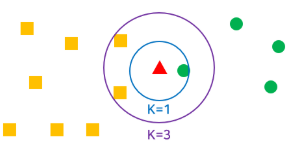

In [ ]:
# 패키지 import
from sklearn.neighbors import KNeighborsClassifier

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

import numpy as np
import matplotlib.pyplot as plt

# from matplotlib.colors import ListedColormap

In [ ]:
# 데이터 로드
iris = load_iris()
X = iris.data  # 특성 데이터
y = iris.target  # 타겟 레이블

# 훈련 데이터와 테스트 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# KNeighborsClassifier?

In [ ]:
# knn = KNeighborsClassifier()

In [ ]:
# # k-NN 분류기 생성 (k=3) .. K 여러 값으로 수정하여 Test
# knn = KNeighborsClassifier(n_neighbors=80)

# # 전체 데이터 수 150 개
# # 50 , 50 , 50
# # k값이 80 이면 ???

# #  맨해튼 거리
# knn_manhattan = KNeighborsClassifier(n_neighbors=3, metric='minkowski', p=1)

# # 코사인 거리
# knn_cosine = KNeighborsClassifier(n_neighbors=3, metric='cosine')

In [ ]:
### weights="distance"
# 가까운 이웃일수록 투표에 더 큰 비중 부여
knn = KNeighborsClassifier(n_neighbors=5, weights="distance")

In [ ]:
# 모델 훈련
knn.fit(X_train, y_train)
# knn_manhattan.fit(X_train, y_train)
# knn_cosine.fit(X_train, y_train)

# Q.학습에 소요되는 시간 얼마나 ?

In [ ]:
# 테스트 데이터에 대한 예측
predictions = knn.predict(X_test)
# predictions2 = knn_manhattan.predict(X_test)

In [ ]:
# 성능 평가
print("Accuracy:", accuracy_score(y_test, predictions))
print("\nClassification Report:\n", classification_report(y_test, predictions))

In [ ]:
### 모델 평가 지표  (n_neighbors=80 으로 하여 값 확)
## Accuracy (정확도): 전체 데이터(30개) 중 정확히 맞춘 사례 비율
#                     19개(클래스 0에서 10개, 클래스 1에서 9개)를 맞추어 0.63

## Macro avg (단순 평균): 3개 클래스의 precision을 평균한 값 (1+0.45+0)/3 ... 데이터 개수와 상관없이 .. 똑같은 비중으로
## Weighted avg (가중 평균): 각 클래스의 데이터 수(Support)에 비례하여 가중치를 두고 계산한 평균

# Precision (정밀도): 모델이 해당 클래스라고 예측한 것 중 실제로 정답인 비율입니다.
# Recall (재현율): 실제 정답인 데이터 중 모델이 해당 클래스로 맞게 찾아낸 비율입니다.
# F1-score: 정밀도와 재현율의 조화 평균으로, 두 지표가 균형을 이룰수록 값이 높아집니다.
# Support: 각 클래스에 속한 실제 데이터의 개수입니다.

In [ ]:
# 성능 평가2 - predictions2
# predictions2 = knn_manhattan.predict(X_test)

# print("Accuracy:", accuracy_score(y_test, predictions2))
# print("\nClassification Report:\n", classification_report(y_test, predictions2))

In [ ]:
### KNN 모델 학습, 추론 프로세스

### knn.fit(X_train, y_train)
# # y_train에 들어 있는 서로 다른 레이블을 통해 클래스 종류를 파악
# (훈련) 데이터의 네 가지 특성값과 해당 꽃 종류 저장.

# knn.predict(X_test)
# 이후 새로운 꽃 데이터가 들어오면 훈련 데이터에서 가까운 이웃 찾음
  # 1. 새로운 꽃의 네 가지 특성을 훈련 데이터의 특성과 비교하여 거리 계산
  # 2. 가장 가까운 이웃 K개 선택
  # 3. 이웃들의 꽃 종류를 확인, 가장 많은 클래스로 분류(예측)
       # ex, n_neighbors=5 이고 가까운 이웃 5개의 정답(=클래스) 가 [1, 2, 1, 0, 1]면 <- 클래스별 득표수
       # setosa(0) : 1, versicolor(1) : 3,  virginica(2) : 1
       # versicolor(클래스 1)로 분류(예측)

In [ ]:
print(knn.classes_)       # [0 1 2]
print(len(knn.classes_))  # 3